# 🌾 Агро-хакатон: кліматичні дані для рекомендацій щодо сівозміни

**Мета проєкту:** допомагати фермерам приймати рішення щодо сівозміни на основі стану ґрунтів та природних умов.
Економічні показники (прибуток, ціни) свідомо **не враховуємо**.

**Що робить цей ноутбук:**
1. Імпортує бібліотеки
2. Завантажує місячні агро-кліматичні дані з NASA POWER API
3. Робить просте очищення та EDA
4. Готує базову кластеризацію K-Means (відправна точка)

## Крок 1. Імпорт бібліотек

Беремо лише найнеобхідніше: роботу з даними (`pandas`, `numpy`), запити до API (`requests`, `json`),
візуалізацію (`seaborn`, `matplotlib`) і базові інструменти `sklearn` для кластеризації.

In [15]:
import json
import requests
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

## Крок 2. Імпорт даних через NASA POWER API

Робимо GET-запит до місячного ендпоінта NASA POWER для однієї точки.

- **Координати:** latitude=40, longitude=-96 (точка на північному кордоні Канзасу; NASA POWER повертає дані для найближчої комірки сітки)
- **Період:** 2025–2026 (місячні дані)
- **Параметри** (замість порожнього `parameters=%3B` з попередньої спроби):
  - `T2M`, `T2M_MAX`, `T2M_MIN` – температура повітря на 2 м (°C): середня, максимальна, мінімальна
  - `PRECTOTCORR` – опади (мм/день)
  - `GWETROOT` – вологість кореневої зони ґрунту (0–1)
  - `GWETTOP` – вологість поверхневого шару ґрунту (0–1)
  - `RH2M` – відносна вологість повітря (%)
  - `ALLSKY_SFC_SW_DWN` – сонячна радіація (кВт·год/м²/день)

> Параметри передаємо через словник `params`: `requests` сам коректно закодує URL.

In [16]:
url = "https://power.larc.nasa.gov/api/temporal/monthly/point"

params = {
    "parameters": "T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,GWETROOT,GWETTOP,RH2M,ALLSKY_SFC_SW_DWN",
    "community": "AG",
    "latitude": 40,
    "longitude": -96,
    "start": 2010,
    "end": 2026,
    "format": "JSON",
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()   # якщо буде помилка запиту – побачимо її одразу

data = response.json()
print("Запит виконано:", response.url)
print("Ключі відповіді:", list(data.keys()))

Запит виконано: https://power.larc.nasa.gov/api/temporal/monthly/point?parameters=T2M%2CT2M_MAX%2CT2M_MIN%2CPRECTOTCORR%2CGWETROOT%2CGWETTOP%2CRH2M%2CALLSKY_SFC_SW_DWN&community=AG&latitude=40&longitude=-96&start=2010&end=2026&format=JSON
Ключі відповіді: ['type', 'geometry', 'properties', 'header', 'messages', 'parameters', 'times']


### Перетворення JSON у DataFrame

Дані лежать у `data["properties"]["parameter"]` у вигляді `{параметр: {"YYYYMM": значення}}`.
Pandas одразу перетворює таку структуру в таблицю, де рядки – місяці, а колонки – параметри.

Особливості NASA POWER:
- ключі виду `2025MM` – це місяці, а `202513` – **середнє за рік**, його прибираємо;
- пропущені значення позначені як `-999`, замінюємо їх на `NaN`.

In [17]:
parameter_dict = data["properties"]["parameter"]

df = pd.DataFrame(parameter_dict)

# прибираємо річні підсумки (ключі, що закінчуються на "13")
df = df[~df.index.str.endswith("13")]

# -999 – це "немає даних"
df = df.replace(-999, np.nan)

# індекс -> дата (перше число місяця)
df.index = pd.to_datetime(df.index, format="%Y%m")
df.index.name = "date"

df.head()

,ALLSKY_SFC_SW_DWN,GWETROOT,GWETTOP,PRECTOTCORR,RH2M,T2M,T2M_MAX,T2M_MIN
date,,,,,,,,
2010-01-01,7.43,0.66,0.69,0.50,88.93,-6.83,11.64,-29.09
2010-02-01,10.33,0.67,0.70,0.90,81.76,-3.56,7.49,-15.95
2010-03-01,12.87,0.69,0.72,2.63,79.88,5.01,23.75,-6.14
2010-04-01,18.39,0.68,0.71,2.95,70.30,13.93,26.64,-0.61
2010-05-01,20.18,0.68,0.71,3.49,74.33,16.29,29.79,2.01


## Крок 3. Очищення та EDA

Використовуємо прості стандартні функції. Спочатку перевіряємо структуру та пропуски.
Місяці, для яких NASA ще не має даних (наприклад, кінець 2026 року), видаляємо.

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 203 entries, 2010-01-01 to 2026-11-01
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ALLSKY_SFC_SW_DWN  199 non-null    float64
 1   GWETROOT           201 non-null    float64
 2   GWETTOP            201 non-null    float64
 3   PRECTOTCORR        201 non-null    float64
 4   RH2M               201 non-null    float64
 5   T2M                201 non-null    float64
 6   T2M_MAX            201 non-null    float64
 7   T2M_MIN            201 non-null    float64
dtypes: float64(8)
memory usage: 14.3 KB


In [19]:
print("Пропуски по колонках:")
print(df.isna().sum())

# видаляємо місяці без даних
df = df.dropna()
print("\nРядків після очищення:", len(df))

Пропуски по колонках:
ALLSKY_SFC_SW_DWN    4
GWETROOT             2
GWETTOP              2
PRECTOTCORR          2
RH2M                 2
T2M                  2
T2M_MAX              2
T2M_MIN              2
dtype: int64

Рядків після очищення: 199


In [20]:
df.tail()

,ALLSKY_SFC_SW_DWN,GWETROOT,GWETTOP,PRECTOTCORR,RH2M,T2M,T2M_MAX,T2M_MIN
date,,,,,,,,
2026-03-01,15.56,0.56,0.57,0.88,63.88,9.30,31.96,-11.87
2026-04-01,17.89,0.58,0.61,4.59,67.40,14.12,29.08,0.45
2026-05-01,22.33,0.59,0.61,4.39,64.31,18.25,33.13,0.94
2026-06-01,21.68,0.61,0.64,4.48,75.17,23.08,33.48,11.25
2026-07-01,22.27,0.55,0.56,4.70,71.60,26.55,38.73,16.82


In [21]:
df.describe()

,ALLSKY_SFC_SW_DWN,GWETROOT,GWETTOP,PRECTOTCORR,RH2M,T2M,T2M_MAX,T2M_MIN
count,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
mean,15.452965,0.580000,0.591809,2.297588,70.337487,11.994724,27.561508,-1.998744
std,5.975909,0.071145,0.085267,1.737652,8.030354,10.548970,8.926348,11.918178
min,4.780000,0.470000,0.350000,0.040000,44.300000,-6.830000,7.490000,-31.660000
25%,10.310000,0.535000,0.535000,0.835000,65.515000,2.520000,20.500000,-10.985000
50%,15.500000,0.560000,0.580000,2.020000,70.300000,12.760000,28.960000,-2.570000
75%,20.520000,0.605000,0.630000,3.375000,75.275000,22.410000,35.295000,9.125000
max,26.910000,0.840000,0.840000,8.920000,90.700000,30.320000,42.660000,18.980000


### Візуалізація 1: кореляції між показниками

Теплова карта показує, які кліматичні параметри пов'язані між собою
(наприклад, температура й сонячна радіація, опади й вологість ґрунту).

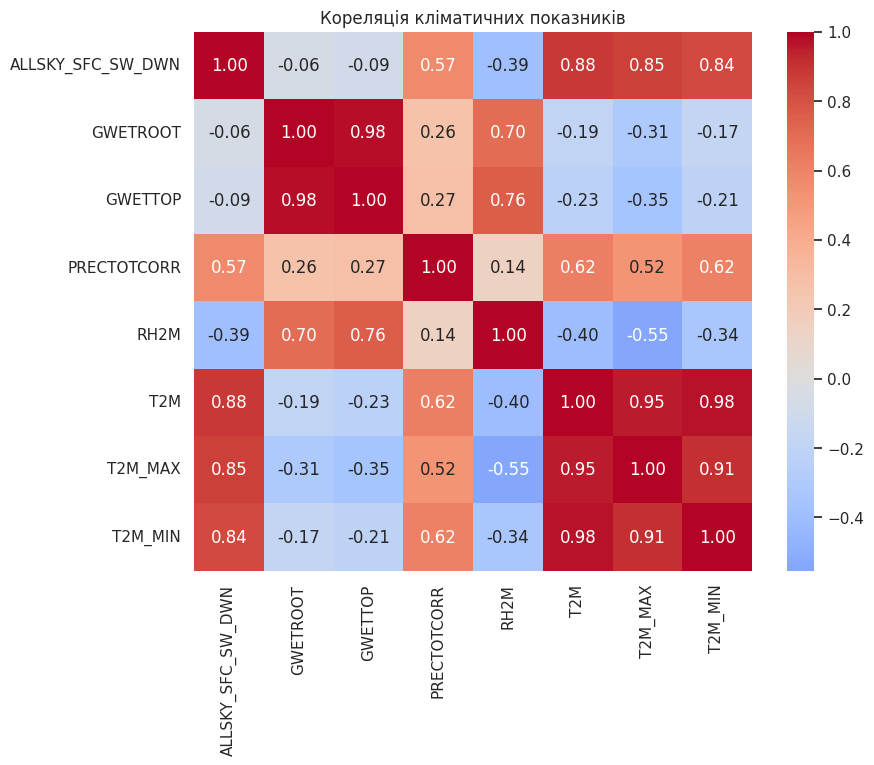

In [22]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Кореляція кліматичних показників")
plt.show()

### Візуалізація 2: температура, опади та вологість ґрунту в часі

Дивимось, як змінюються ключові показники по місяцях.

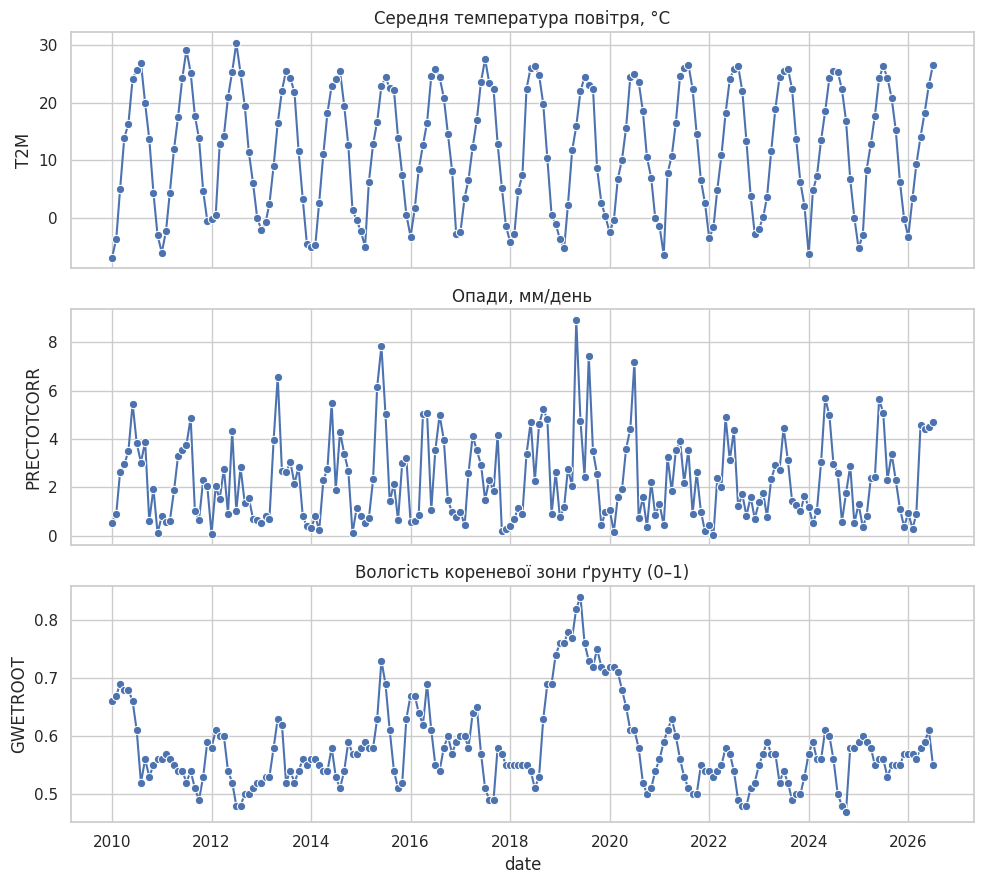

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

sns.lineplot(data=df, x=df.index, y="T2M", marker="o", ax=axes[0])
axes[0].set_title("Середня температура повітря, °C")

sns.lineplot(data=df, x=df.index, y="PRECTOTCORR", marker="o", ax=axes[1])
axes[1].set_title("Опади, мм/день")

sns.lineplot(data=df, x=df.index, y="GWETROOT", marker="o", ax=axes[2])
axes[2].set_title("Вологість кореневої зони ґрунту (0–1)")

plt.tight_layout()
plt.show()

## Крок 4. Unsupervised Learning (підготовка)

Розмічених даних немає, тому використовуємо кластеризацію **K-Means** як відправну точку:
чи можна розбити місяці на групи зі схожими кліматичними умовами?

План:
1. Беремо числові ознаки
2. Стандартизуємо їх (`StandardScaler`), щоб градуси, міліметри та частки одиниці були порівнянні
3. Робимо базовий `fit` K-Means

> Рядків у нас небагато (місячні дані за ~2 роки), тому результат слід сприймати лише як перший погляд на структуру даних.

In [24]:
feature_names = df.columns.tolist()

# Стандартизуємо дані (середнє = 0, дисперсія = 1)
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(df)

# Робимо з цього зручний DataFrame для подальшої роботи
df_ml = pd.DataFrame(X_scaled_array, columns=feature_names, index=df.index)

print("Дані стандартизовано і готові для тренування моделі.")
print("Використовуй змінну `df_ml` для кластеризації/навчання.")
df_ml.head()

Дані стандартизовано і готові для тренування моделі.
Використовуй змінну `df_ml` для кластеризації/навчання.


,ALLSKY_SFC_SW_DWN,GWETROOT,GWETTOP,PRECTOTCORR,RH2M,T2M,T2M_MAX,T2M_MIN
date,,,,,,,,
2010-01-01,-1.345937,1.127300,1.154476,-1.037102,2.321119,-1.789009,-1.788152,-2.278837
2010-02-01,-0.859432,1.268212,1.272050,-0.806325,1.426004,-1.478244,-2.254240,-1.173539
2010-03-01,-0.433320,1.550037,1.507199,0.191782,1.191302,-0.663794,-0.428072,-0.348350
2010-04-01,0.492719,1.409124,1.389625,0.376403,-0.004680,0.183919,-0.103495,0.116817
2010-05-01,0.793010,1.409124,1.389625,0.687951,0.498432,0.408202,0.250283,0.337204


In [25]:
# ---------------------------------------------------------
# Приклад базового запуску K-Means:
#
# from sklearn.cluster import KMeans
# kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
# df['cluster'] = kmeans.fit_predict(df_ml)
# ---------------------------------------------------------